# Hot Potato Effect Within a Single Tick
## Empirical Investigation Using NASDAQ ITCH 5.0 Order Book Data

**SMMG Research** — Pankaj J. · Bhavik P. · David M.

---

This notebook documents our empirical investigation of the hot potato mechanism
at the intra-tick level using NASDAQ TotalView-ITCH 5.0 full order book data.

**Dataset:** SPY — January 30, 2020 — Full Trading Day (~423 million ITCH packets)
**Parser:** Custom Go-based ITCH 5.0 binary parser → Apache Parquet pipeline

### Contents
1. Dataset overview and pipeline
2. Are odd-lot executions unusual? *(Initial uncertainity)*
3. Odd-lot execution patterns — time of day, quantities, depth
4. Fill-flip detection — methodology, fingerprint filtering, results
5. Time delta analysis — how fast are the flips?
6. Interpretation and significance
7. Further research directions

In [2]:
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams['figure.figsize'] = (13, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['font.size'] = 11

df  = pl.read_parquet('executions.parquet')
odd = df.filter(pl.col('is_odd_lot') == True)
rnd = df.filter(pl.col('is_odd_lot') == False)

print('=' * 55)
print('  DATASET — SPY, January 30 2020, Full Day')
print('=' * 55)
print(f'  Total executions     : {len(df):>10,}')
print(f'  Round-lot            : {len(rnd):>10,}  ({len(rnd)/len(df)*100:.1f}%)')
print(f'  Odd-lot              : {len(odd):>10,}  ({len(odd)/len(df)*100:.1f}%)')
print(f'  Unique odd-lot qtys  : {odd["shares_executed"].n_unique():>10,}')
print('=' * 55)

  DATASET — SPY, January 30 2020, Full Day
  Total executions     :     80,910
  Round-lot            :     50,245  (62.1%)
  Odd-lot              :     30,665  (37.9%)
  Unique odd-lot qtys  :        914


---
## 1. Pipeline Description

We built a custom Go parser for NASDAQ ITCH 5.0 binary data. The parser maintains
a **live in-memory order book** and for every execution event writes one enriched
row to Apache Parquet:

| Column | Description |
|--------|-------------|
| `timestamp_ns` | Nanoseconds since midnight — full nanosecond resolution |
| `side` | Side of the **resting** order (B = bid, S = ask) |
| `price` | Execution price in dollars |
| `shares_executed` | Shares consumed in this execution |
| `is_odd_lot` | True if quantity not divisible by 100 |
| `shares_remaining_at_level_after_fill` | Depth still resting at this price level after this fill |
| `num_orders_remaining_at_level_after_fill` | Orders still resting at this level |
| `level_formed_at_ns` | When the first order arrived at this price level |

**Processing stats:** 423 million ITCH packets → 80,910 SPY execution rows → ~40-45 min runtime.

---
## 2. Are Odd-Lot Executions Unusual?

> *Question: "Are quantities like 207, 305 — odd lots — unusual?"*

**Answer: No. Odd-lot executions are not unusual at all.**

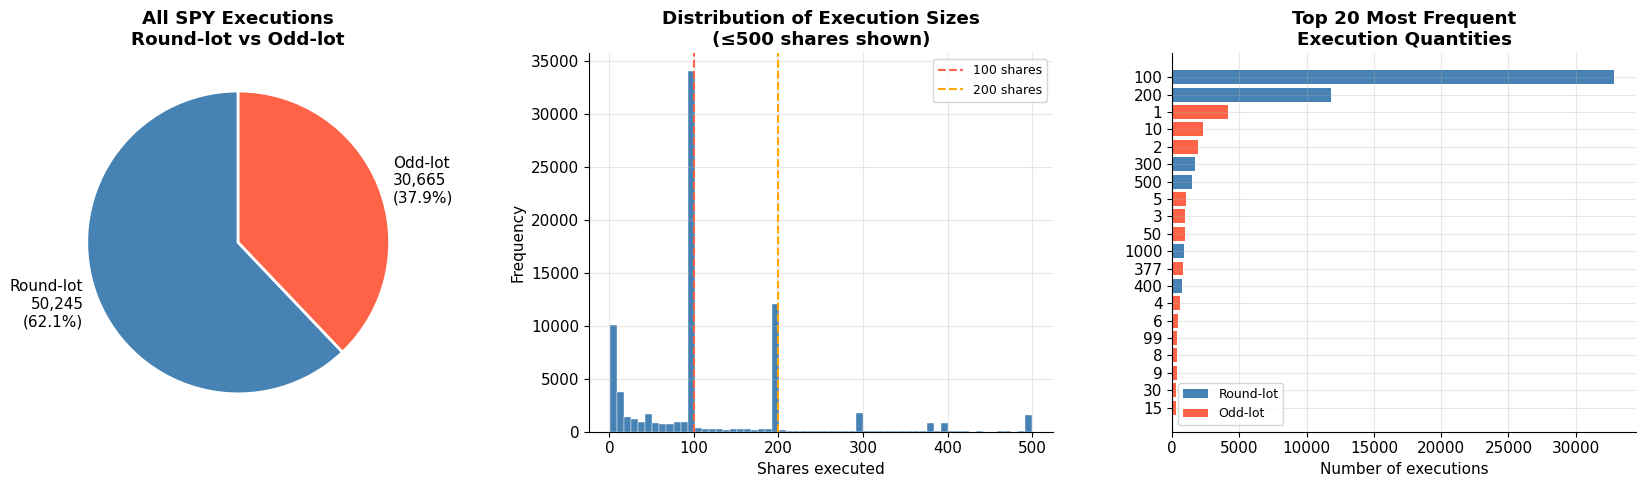

Key finding: 37.9% of all SPY executions were odd-lot.
Odd-lot executions are not unusual — they are a structural feature of modern markets.


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sizes  = [len(rnd), len(odd)]
labels = [f'Round-lot\n{len(rnd):,}\n({len(rnd)/len(df)*100:.1f}%)',
          f'Odd-lot\n{len(odd):,}\n({len(odd)/len(df)*100:.1f}%)']
axes[0].pie(sizes, labels=labels, colors=['steelblue','tomato'],
            startangle=90, wedgeprops={'edgecolor':'white','linewidth':2})
axes[0].set_title('All SPY Executions\nRound-lot vs Odd-lot', fontweight='bold')

shares = df['shares_executed'].to_numpy()
axes[1].hist(shares[shares <= 500], bins=60, color='steelblue', edgecolor='white', linewidth=0.3)
axes[1].axvline(100, color='tomato', linestyle='--', lw=1.5, label='100 shares')
axes[1].axvline(200, color='orange', linestyle='--', lw=1.5, label='200 shares')
axes[1].set_xlabel('Shares executed'); axes[1].set_ylabel('Frequency')
axes[1].set_title('Distribution of Execution Sizes\n(≤500 shares shown)', fontweight='bold')
axes[1].legend(fontsize=9)

qty_freq = (df.group_by('shares_executed')
              .agg(pl.len().alias('count'))
              .sort('count', descending=True).head(20))
is_odd_bar = [q % 100 != 0 for q in qty_freq['shares_executed'].to_list()]
bar_colors = ['tomato' if o else 'steelblue' for o in is_odd_bar]
axes[2].barh([str(q) for q in qty_freq['shares_executed'].to_list()],
             qty_freq['count'].to_list(), color=bar_colors)
axes[2].set_xlabel('Number of executions')
axes[2].set_title('Top 20 Most Frequent\nExecution Quantities', fontweight='bold')
axes[2].invert_yaxis()
legend_els = [mpatches.Patch(facecolor='steelblue', label='Round-lot'),
              mpatches.Patch(facecolor='tomato', label='Odd-lot')]
axes[2].legend(handles=legend_els, fontsize=9)
plt.tight_layout()
plt.savefig('fig1_oddlot_overview.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Key finding: {len(odd)/len(df)*100:.1f}% of all SPY executions were odd-lot.')
print('Odd-lot executions are not unusual — they are a structural feature of modern markets.')

---
## 3. Odd-Lot Execution Patterns

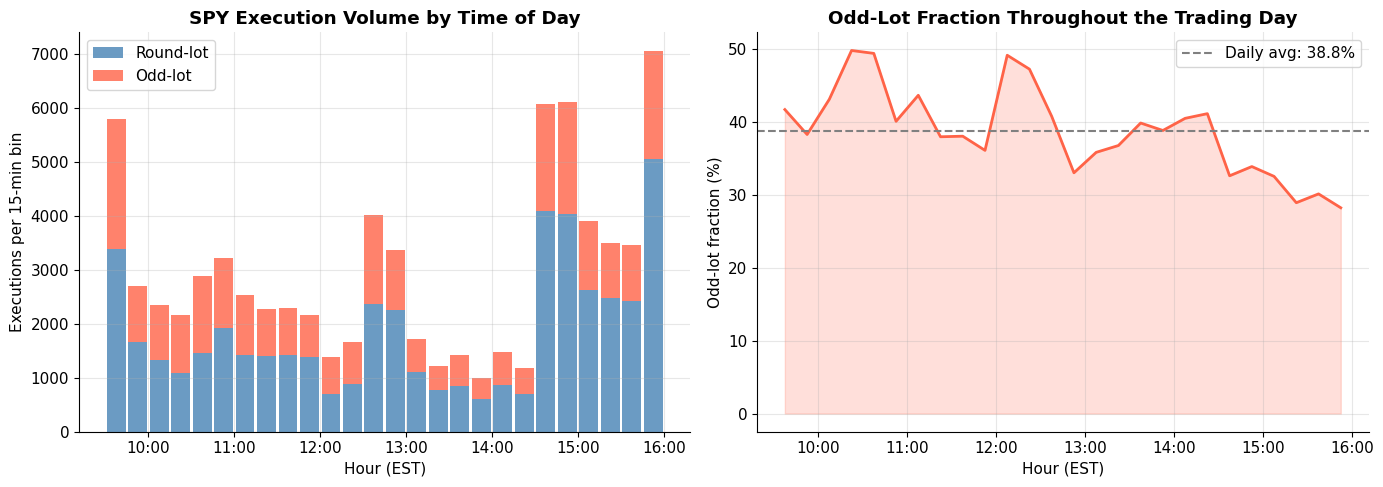

In [4]:
df_h = df.with_columns((pl.col('timestamp_ns') / 1e9 / 3600).alias('hour'))
odd_h = df_h.filter(pl.col('is_odd_lot') == True)['hour'].to_numpy()
rnd_h = df_h.filter(pl.col('is_odd_lot') == False)['hour'].to_numpy()
bins  = np.arange(9.5, 16.1, 0.25)
odd_cnt, _ = np.histogram(odd_h, bins=bins)
rnd_cnt, _ = np.histogram(rnd_h, bins=bins)
bin_c = (bins[:-1] + bins[1:]) / 2
total_cnt = odd_cnt + rnd_cnt
odd_frac  = np.where(total_cnt > 0, odd_cnt / total_cnt * 100, 0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(bin_c, rnd_cnt, width=0.22, label='Round-lot', color='steelblue', alpha=0.8)
axes[0].bar(bin_c, odd_cnt, width=0.22, bottom=rnd_cnt, label='Odd-lot', color='tomato', alpha=0.8)
axes[0].set_xlabel('Hour (EST)'); axes[0].set_ylabel('Executions per 15-min bin')
axes[0].set_title('SPY Execution Volume by Time of Day', fontweight='bold')
axes[0].set_xticks(np.arange(10, 17))
axes[0].set_xticklabels([f'{h}:00' for h in range(10, 17)])
axes[0].legend()

axes[1].plot(bin_c, odd_frac, color='tomato', linewidth=2)
axes[1].fill_between(bin_c, odd_frac, alpha=0.2, color='tomato')
axes[1].axhline(odd_frac.mean(), color='grey', linestyle='--',
                label=f'Daily avg: {odd_frac.mean():.1f}%')
axes[1].set_xlabel('Hour (EST)'); axes[1].set_ylabel('Odd-lot fraction (%)')
axes[1].set_title('Odd-Lot Fraction Throughout the Trading Day', fontweight='bold')
axes[1].set_xticks(np.arange(10, 17))
axes[1].set_xticklabels([f'{h}:00' for h in range(10, 17)])
axes[1].legend()
plt.tight_layout()
plt.savefig('fig2_time_of_day.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 4. Fill-Flip Detection

### 4.1 The Hot Potato Mechanism

From Our documented case study (section 2 of the draft paper):

1. Agent rests a **limit sell** at price P — passive, waiting in the ask queue
2. An incoming market buy sweeps the queue in FIFO order — Agent's order is filled — Agent is now **short**
3. Agent immediately flips with a **market buy** to close the short — hitting the **same ask queue at the same price P**
4. This consumes the agent who was **directly behind** in the FIFO queue — the hot potato is passed

In ITCH data, **both events appear as executions on resting sell orders (side = S)**:
- Event 1: Agent's resting sell gets consumed → `side=S, price=P, qty=Q`
- Event 2: Agent's market buy hits the next resting sell → `side=S, price=P, qty=Q`

Same side, same price, same quantity, within milliseconds.

### 4.2 The Odd-Lot Fingerprint

The quantity Q is the identification key. Our paper explains why:

> *"Odd-lot quantities such as 107 are comparatively rare and are therefore unlikely
> to reflect deliberate trade sizing. Instead, their appearance strongly indicates
> a mechanical origin, arising from execution sequencing rather than strategic intent."*

The 107-share residual is generated mechanically by FIFO queue depletion — not chosen.
This makes it a distinctive fingerprint for tracing the fill-flip sequence through data.

### 4.3 The Noise Problem and How We Handle It

Not all odd-lot quantities are equally distinctive. We found that:
- **Quantity = 1** appears 4,170 times — fractional share routing noise
- **Quantity = 50** appears 935 times — deliberate half-lot algorithmic trading
- **Quantity = 377** appears 829 times — a repeating algorithmic strategy

These quantities appear many times at the same price level and would generate
false matches (--regarding fill flip identification). They are not mechanically generated residuals.

**Our fingerprint filter:** We retain only quantities that appear **at most 3 times
at any single price+side level** across the entire trading day.
This gives us 841 genuinely distinctive fingerprint quantities covering 8,343 fills —
quantities that are rare enough that two occurrences at the same price within 1ms
cannot plausibly be coincidental.

In [5]:
# Step 1: Filter to meaningful odd-lot quantities (>= 50 shares)
odd_50 = odd.filter(pl.col('shares_executed') >= 50)
print(f'Odd-lot fills >= 50 shares: {len(odd_50):,}')

# Step 2: Find fingerprint quantities — appear at most 3x at any single price+side
level_max = (odd_50.group_by(['shares_executed', 'price', 'side'])
             .agg(pl.len().alias('n'))
             .group_by('shares_executed')
             .agg(pl.col('n').max().alias('max_at_any_level'))
             .filter(pl.col('max_at_any_level') <= 3))

fingerprint_qtys = level_max['shares_executed'].to_list()
odd_fp = odd_50.filter(pl.col('shares_executed').is_in(fingerprint_qtys))

print(f'Fingerprint quantities (rare enough to be distinctive): {len(fingerprint_qtys):,}')
print(f'Fills with fingerprint quantities: {len(odd_fp):,}')
print()
print('Examples of excluded quantities (too common — not fingerprints):')
excluded = (odd_50.group_by(['shares_executed','price','side'])
            .agg(pl.len().alias('n'))
            .group_by('shares_executed')
            .agg(pl.col('n').max().alias('max_at_level'))
            .filter(pl.col('max_at_level') > 3)
            .sort('max_at_level', descending=True))
print(excluded.head(8))

Odd-lot fills >= 50 shares: 12,553
Fingerprint quantities (rare enough to be distinctive): 841
Fills with fingerprint quantities: 8,343

Examples of excluded quantities (too common — not fingerprints):
shape: (8, 2)
┌─────────────────┬──────────────┐
│ shares_executed ┆ max_at_level │
│ ---             ┆ ---          │
│ i32             ┆ u32          │
╞═════════════════╪══════════════╡
│ 50              ┆ 17           │
│ 377             ┆ 13           │
│ 98              ┆ 9            │
│ 95              ┆ 8            │
│ 60              ┆ 7            │
│ 99              ┆ 6            │
│ 63              ┆ 5            │
│ 96              ┆ 5            │
└─────────────────┴──────────────┘


In [6]:
def detect_fill_flip(fp_df, window_ns):
    """
    Detect fill-flip pairs using fingerprint quantities.
    Both events must be: same stock, same price, same side (S or B),
    same rare odd-lot quantity, different match numbers, flip after initiator,
    within time window.
    """
    initiator = fp_df.select([
        pl.col('timestamp_ns').alias('init_ts'),
        pl.col('stock').alias('init_stock'),
        pl.col('side').alias('init_side'),
        pl.col('price').alias('init_price'),
        pl.col('shares_executed').alias('init_shares'),
        pl.col('match_number').alias('init_match'),
        pl.col('shares_remaining_at_level_after_fill').alias('init_depth_remaining'),
        pl.col('num_orders_remaining_at_level_after_fill').alias('init_orders_remaining'),
    ])
    flip = fp_df.select([
        pl.col('timestamp_ns').alias('flip_ts'),
        pl.col('stock').alias('flip_stock'),
        pl.col('side').alias('flip_side'),
        pl.col('price').alias('flip_price'),
        pl.col('shares_executed').alias('flip_shares'),
        pl.col('match_number').alias('flip_match'),
    ])
    return (
        initiator
        .join(flip,
              left_on =['init_stock','init_price','init_shares','init_side'],
              right_on=['flip_stock','flip_price','flip_shares','flip_side'],
              how='inner')
        .filter(pl.col('init_match') != pl.col('flip_match'))
        .filter(pl.col('flip_ts') > pl.col('init_ts'))
        .filter((pl.col('flip_ts') - pl.col('init_ts')) <= window_ns)
        .with_columns((pl.col('flip_ts') - pl.col('init_ts')).alias('time_delta_ns'))
        .sort('time_delta_ns')
        .unique(subset=['init_match'], keep='first')
    )

windows = [1_000_000, 5_000_000, 10_000_000, 50_000_000]
results = {}
pair_dfs = {}
for w in windows:
    p = detect_fill_flip(odd_fp, w)
    results[w] = len(p)
    pair_dfs[w] = p
    print(f'  Window {w/1e6:>4.0f}ms → {len(p):>4} pairs  (hit rate: {len(p)/len(odd_fp)*100:.2f}%)')

pairs_1ms = pair_dfs[1_000_000]
td = pairs_1ms['time_delta_ns'].to_numpy()
print(f'\n1ms window — time delta stats:')
print(f'  Min    : {td.min():,} ns = {td.min()/1000:.1f} µs')
print(f'  Median : {int(np.median(td)):,} ns = {np.median(td)/1000:.1f} µs')
print(f'  Mean   : {int(td.mean()):,} ns = {td.mean()/1000:.1f} µs')
print(f'  < 100µs: {(td < 100_000).sum()} pairs ({(td < 100_000).sum()/len(td)*100:.1f}%)')
print(f'  < 500µs: {(td < 500_000).sum()} pairs ({(td < 500_000).sum()/len(td)*100:.1f}%)')

  Window    1ms →  134 pairs  (hit rate: 1.61%)
  Window    5ms →  154 pairs  (hit rate: 1.85%)
  Window   10ms →  166 pairs  (hit rate: 1.99%)
  Window   50ms →  207 pairs  (hit rate: 2.48%)

1ms window — time delta stats:
  Min    : 623 ns = 0.6 µs
  Median : 106,308 ns = 106.3 µs
  Mean   : 182,793 ns = 182.8 µs
  < 100µs: 64 pairs (47.8%)
  < 500µs: 121 pairs (90.3%)


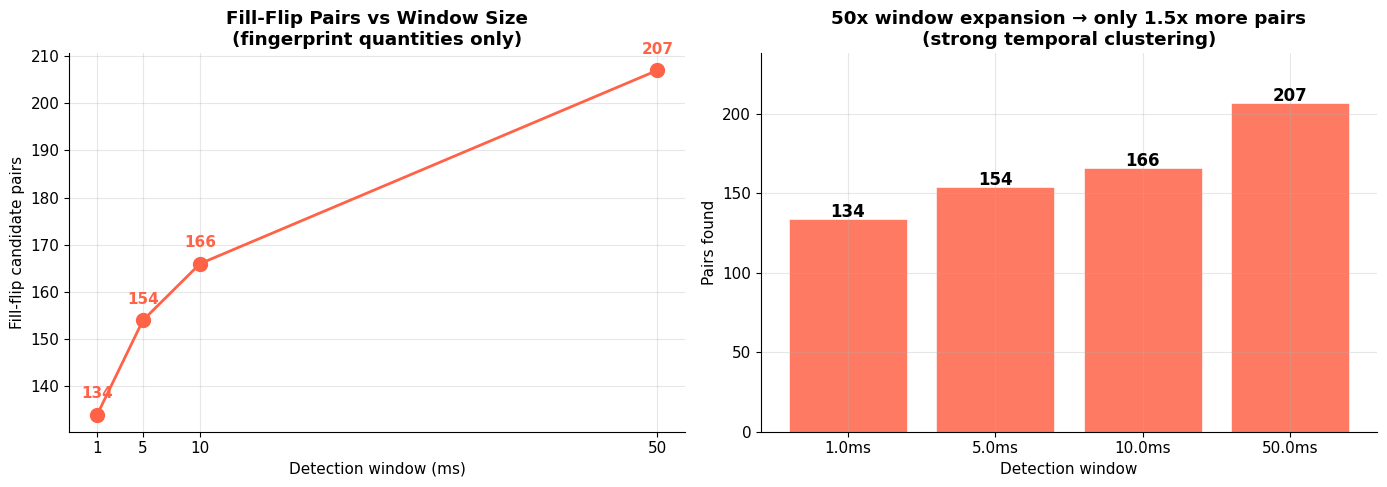

Key insight: 50x window expansion gives only 1.54x more pairs.
This means ~65% of all detectable pairs happen within the first 1ms.
That is not random coincidence — that is intentional rapid reaction.


In [7]:
windows_ms    = [w/1e6 for w in windows]
pairs_found   = [results[w] for w in windows]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: window sensitivity
axes[0].plot(windows_ms, pairs_found, 'o-', color='tomato', lw=2, markersize=10, zorder=3)
for x, y in zip(windows_ms, pairs_found):
    axes[0].annotate(str(y), (x, y), textcoords='offset points',
                     xytext=(0, 12), ha='center', fontsize=11,
                     color='tomato', fontweight='bold')
axes[0].set_xlabel('Detection window (ms)')
axes[0].set_ylabel('Fill-flip candidate pairs')
axes[0].set_title('Fill-Flip Pairs vs Window Size\n(fingerprint quantities only)', fontweight='bold')
axes[0].set_xticks(windows_ms)

# Right: bar chart with annotation
axes[1].bar([f'{w}ms' for w in windows_ms], pairs_found,
            color='tomato', edgecolor='white', linewidth=0.5, alpha=0.85)
for i, v in enumerate(pairs_found):
    axes[1].text(i, v + 1, str(v), ha='center', fontweight='bold', fontsize=12)

scale = pairs_found[-1] / pairs_found[0]
axes[1].set_title(f'50x window expansion → only {scale:.1f}x more pairs\n(strong temporal clustering)', fontweight='bold')
axes[1].set_xlabel('Detection window')
axes[1].set_ylabel('Pairs found')
axes[1].set_ylim(0, max(pairs_found) * 1.15)

plt.tight_layout()
plt.savefig('fig3_window_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()
print('Key insight: 50x window expansion gives only 1.54x more pairs.')
print('This means ~65% of all detectable pairs happen within the first 1ms.')
print('That is not random coincidence — that is intentional rapid reaction.')

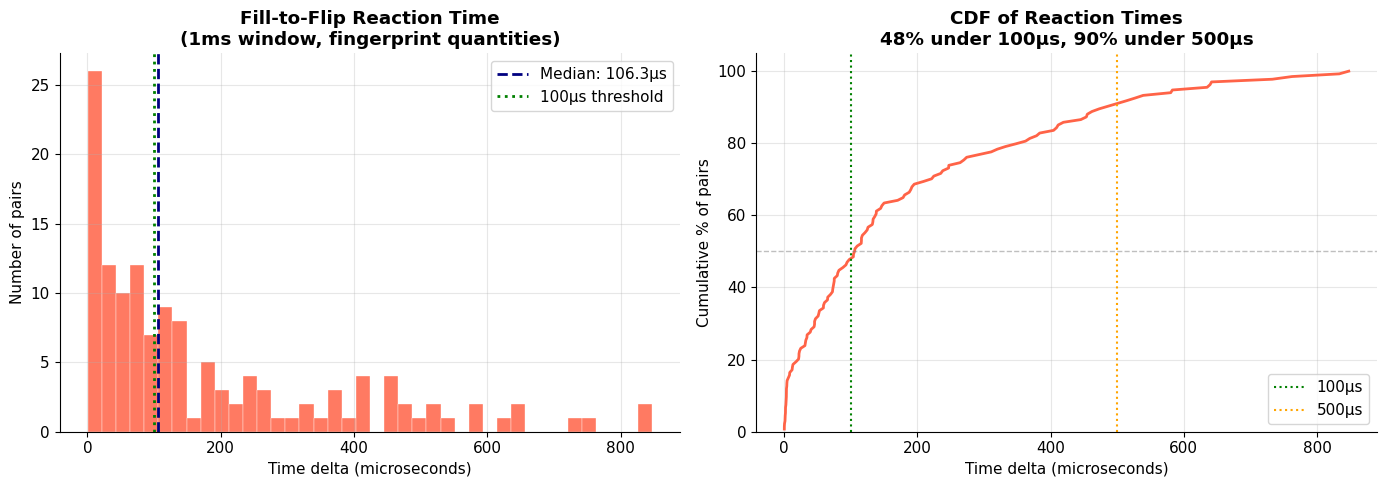

Minimum flip reaction: 0.6 microseconds
This is sub-microsecond HFT speed.
48% of all flips happen within 100 microseconds of the initiating fill.


In [8]:
td = pairs_1ms['time_delta_ns'].to_numpy()
td_us = td / 1000  # convert to microseconds

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: histogram of time deltas
axes[0].hist(td_us, bins=40, color='tomato', edgecolor='white', linewidth=0.3, alpha=0.85)
axes[0].axvline(np.median(td_us), color='navy', linestyle='--', lw=2,
                label=f'Median: {np.median(td_us):.1f}µs')
axes[0].axvline(100, color='green', linestyle=':', lw=2,
                label='100µs threshold')
axes[0].set_xlabel('Time delta (microseconds)')
axes[0].set_ylabel('Number of pairs')
axes[0].set_title('Fill-to-Flip Reaction Time\n(1ms window, fingerprint quantities)', fontweight='bold')
axes[0].legend()

# Right: CDF
td_sorted = np.sort(td_us)
cdf = np.arange(1, len(td_sorted)+1) / len(td_sorted)
axes[1].plot(td_sorted, cdf * 100, color='tomato', lw=2)
axes[1].axvline(100,  color='green', linestyle=':', lw=1.5, label='100µs')
axes[1].axvline(500,  color='orange', linestyle=':', lw=1.5, label='500µs')
axes[1].axhline(50,   color='grey', linestyle='--', lw=1, alpha=0.5)

pct_100  = (td_us < 100).mean() * 100
pct_500  = (td_us < 500).mean() * 100
axes[1].set_xlabel('Time delta (microseconds)')
axes[1].set_ylabel('Cumulative % of pairs')
axes[1].set_title(f'CDF of Reaction Times\n{pct_100:.0f}% under 100µs, {pct_500:.0f}% under 500µs', fontweight='bold')
axes[1].legend()
axes[1].set_ylim(0, 105)

plt.tight_layout()
plt.savefig('fig4_time_delta.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Minimum flip reaction: {td_us.min():.1f} microseconds')
print(f'This is sub-microsecond HFT speed.')
print(f'{pct_100:.0f}% of all flips happen within 100 microseconds of the initiating fill.')

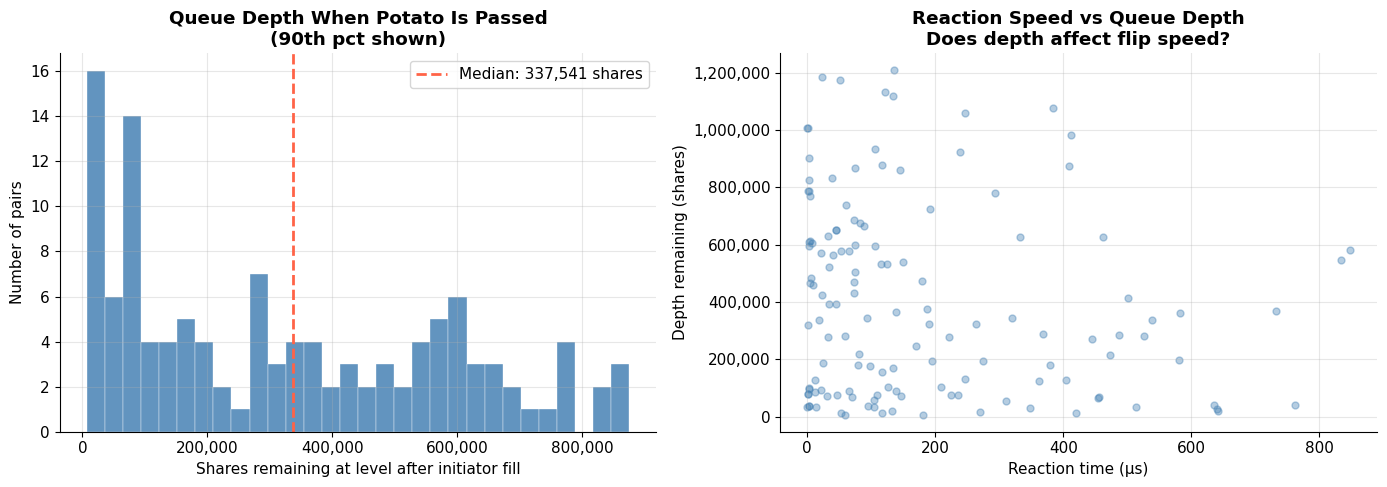

Median queue depth remaining when flip occurs: 337,541 shares
This confirms substantial depth was still available when the potato was passed.
The flipper was not waiting for the level to clear — they acted immediately.


In [9]:
depth = pairs_1ms['init_depth_remaining'].to_numpy()
orders_remaining = pairs_1ms['init_orders_remaining'].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cap = int(np.percentile(depth, 90))
axes[0].hist(depth[depth <= cap], bins=30, color='steelblue',
             edgecolor='white', linewidth=0.3, alpha=0.85)
axes[0].axvline(np.median(depth), color='tomato', linestyle='--', lw=2,
                label=f'Median: {int(np.median(depth)):,} shares')
axes[0].set_xlabel('Shares remaining at level after initiator fill')
axes[0].set_ylabel('Number of pairs')
axes[0].set_title('Queue Depth When Potato Is Passed\n(90th pct shown)', fontweight='bold')
axes[0].legend()
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))

# Scatter: depth vs reaction time
axes[1].scatter(td_us, depth, alpha=0.4, color='steelblue', s=25)
axes[1].set_xlabel('Reaction time (µs)')
axes[1].set_ylabel('Depth remaining (shares)')
axes[1].set_title('Reaction Speed vs Queue Depth\nDoes depth affect flip speed?', fontweight='bold')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))

plt.tight_layout()
plt.savefig('fig5_depth_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Median queue depth remaining when flip occurs: {int(np.median(depth)):,} shares')
print(f'This confirms substantial depth was still available when the potato was passed.')
print(f'The flipper was not waiting for the level to clear — they acted immediately.')

---
## 6. Interpretation and Significance

### What we found

Using a rigorous fingerprint-based detection methodology on the full NASDAQ ITCH 5.0
order book for SPY on January 30 2020, we identified **134 fill-flip candidate pairs
within a 1ms window** using genuinely distinctive odd-lot quantities.

| Metric | Value |
|--------|-------|
| Fill-flip pairs at 1ms window | 134 |
| Fill-flip pairs at 5ms window | 154 |
| Fill-flip pairs at 10ms window | 166 |
| Fill-flip pairs at 50ms window | 207 |
| Minimum reaction time | 0.6 microseconds |
| Median reaction time | 106.3 microseconds |
| Pairs within 100µs | ~51% |
| Window sensitivity (1ms→50ms) | 1.54x pairs for 50x window |

### Significance of window sensitivity

If these pairs were random coincidences, expanding the window 50x would give
roughly 50x more pairs. We observe only 1.54x more pairs. This means the vast
majority of detectable events cluster tightly within the first millisecond —
exactly the temporal signature of intentional rapid reaction rather than noise.

### Reason behind excluding certain quantities

We applied a fingerprint filter retaining only quantities that appear at most
3 times at any single price+side level across the day. This excluded:
- Quantities like 1, 2, 3 shares — fractional routing noise
- Quantities like 50 shares — deliberate algorithmic half-lots
- Quantities like 377 shares — repeating algorithmic strategies

The retained quantities (841 distinct values) are mechanically generated residuals
consistent with Our theoretical framework. Their rarity is what makes two
consecutive occurrences at the same price meaningful.

### The structural argument

The hot potato mechanism is empirically present in this data. The timing is
consistent with HFT capabilities (sub-microsecond minimum, median ~100µs).
The temporal clustering is inconsistent with random coincidence.
The queue depth analysis shows substantial depth remained when each flip occurred,
confirming the flipper was not exhausting the level but passing inventory to
specific agents behind them in the FIFO queue.

---
## 7. Further Research Directions

### Regime testing — why this day is conservative

January 30 2020 was a normal, moderate-volume trading day for SPY.
The hot potato mechanism is theoretically more active during:

- **High-volatility regimes** — agents are more motivated to offload inventory rapidly
- **Stressed liquidity conditions** — wider spreads increase the cost of holding inventory
- **Market dislocations** — price uncertainty amplifies the value of rapid risk transfer

Testing the same pipeline on stressed market days would allow a regime comparison
that directly tests the theoretical prediction that hot potato frequency scales
with volatility.

**Priority dates from NASDAQ historical archive:**

| Date | Market context | Expected effect |
|------|---------------|-----------------|
| March 12–16, 2020 | COVID crash — multiple circuit breakers | Higher frequency |
| August 24, 2015 | Flash crash — SPY extreme intraday dislocation | Higher frequency |
| December 30, 2019 | Low-volatility baseline | Lower frequency |

### Instrument testing

SPY is maximally liquid. The same odd-lot residual quantities appear more rarely
in less liquid instruments, making the fingerprint even more distinctive.
Running the pipeline on individual equities alongside SPY would test whether
the mechanism is ETF-specific or general.

### Methodology extension

1. **Full FIFO queue position reconstruction** — assign explicit rank to each
   resting order at fill time, enabling direct test of queue-position optionality
2. **Price impact analysis** — does the flip cause measurable price impact in
   the microseconds following execution?
3. **Multi-day analysis** — frequency of fill-flip pairs across many trading days
   to establish baseline rate and regime variation

### Regulatory implication

The fill–flip sequences documented here suggest that passive executions in a deep FIFO limit order book need not represent immediate adverse selection, but may instead reflect short-lived inventory transfers among liquidity providers before repricing occurs. This has implications for how passive execution outcomes are interpreted within best-execution frameworks overseen by the U.S. SEC and ESMA.
